
# 20 — Analisi di una partita DR3 con telecamera fissa

## Contesto e obiettivi

Il notebook analizza una registrazione della partita **Virtus Pomezia – Samurai Basket Aprilia** (Serie DR3), acquisita con una telecamera grandangolare fissa alla risoluzione di 854×480 pixel. L'inquadratura comprende l'intero campo di gioco.

Le verifiche preliminari effettuate nel notebook 19 hanno evidenziato alcune criticità nell'applicazione della pipeline sviluppata per i video NBA:

- Il modello di riconoscimento dei keypoint del campo identifica erroneamente alcuni elementi del soffitto, producendo omografie non utilizzabili.
- Il detector dei giocatori, con risoluzione di inferenza pari a 640 pixel, rileva prevalentemente i soggetti più vicini alla telecamera.
- Il detector della palla non produce rilevamenti nelle sequenze analizzate.

L'obiettivo è verificare l'applicabilità della pipeline a un contesto di acquisizione differente, introducendo adattamenti specifici per la geometria della ripresa e per le dimensioni degli oggetti nell'immagine.

L'analisi comprende la calibrazione manuale della telecamera, il confronto tra diverse configurazioni di detection, la ricostruzione delle traiettorie e la valutazione quantitativa delle prestazioni mediante annotazioni manuali.

## Struttura del notebook

| Sezione | Descrizione |
|---|---|
| **A — Preparazione video** | Estrazione di una clip di 60 secondi a 30 fps, codificata in H.264. |
| **B — Calibrazione geometrica** | Stima manuale dell'omografia, correzione della distorsione grandangolare e valutazione dell'errore di proiezione mediante validazione leave-one-out. |
| **C — Analisi della palla** | Stima della dimensione apparente della palla, espressa in pixel, in diverse regioni del campo. |
| **D — Rilevamento dei giocatori** | Confronto tra inferenza sull'immagine completa e inferenza su regioni del campo ritagliate e ingrandite. |
| **E–F — Tracking e classificazione** | Tracking dei giocatori mediante BoT-SORT, ricostruzione delle coordinate in metri e classificazione delle squadre in base al colore delle divise. |
| **G — Analisi spaziale** | Generazione della mappa 2D, delle heatmap e delle stime di distanza percorsa e velocità. |
| **H — Visualizzazione** | Produzione di un video dimostrativo con sovrapposizione della mini-mappa del campo. |
| **I — Rilevamento della palla** | Misurazione della percentuale di frame nei quali il detector individua la palla. |
| **J — Sintesi dei risultati** | Raccolta dei risultati principali e delle limitazioni osservate. |
| **K — Valutazione sperimentale** | Costruzione della ground truth su circa 40 frame, studio di ablazione degli adattamenti, analisi della recall in funzione della dimensione dei giocatori e verifica dei requisiti del sistema. |

## Ambito dell'analisi

L'esperimento si concentra sul rilevamento degli oggetti, sul tracking e sulla ricostruzione delle posizioni dei giocatori.

Il riconoscimento automatico degli eventi di gioco non viene eseguito, poiché richiede informazioni affidabili sulla posizione della palla. Non viene inoltre effettuata la lettura automatica del punteggio, a causa delle dimensioni ridotte del tabellone LED nell'inquadratura.

Di conseguenza, le regole di riconoscimento degli eventi sviluppate nel notebook 15 non vengono applicate a questa registrazione.

## Output e valutazione

I risultati vengono salvati nella directory:

`events_amatoriali/<clip>/`

Le sezioni **A–J** comprendono la preparazione della sequenza, l'elaborazione automatica e le visualizzazioni.

La sezione **K** prevede due fasi:
- **K1:** preparazione dei frame e delle annotazioni di riferimento.
- **K2:** valutazione quantitativa mediante confronto con la ground truth annotata.

La distinzione tra le due fasi consente di mantenere separata la generazione delle predizioni dalla loro valutazione.

## Ambiente di esecuzione

Il notebook è progettato per Google Colab con accelerazione GPU NVIDIA T4 o L4.

Non è richiesta una chiave API Roboflow.


In [1]:
%pip install -q ultralytics trackers supervision
# dopo il pip: Runtime -> Riavvia sessione, poi esegui dalla cella successiva

In [2]:
import sys
if 'triton' not in sys.modules: sys.modules['triton'] = None
import sys, os
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Tesi_Basket')
else:
    ROOT = Path(r'F:\Tesi Basket')
assert ROOT.is_dir(), f'Cartella del progetto non trovata: {ROOT}'
import json, time, subprocess, shutil, itertools
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
print('Progetto:', ROOT)

Mounted at /content/drive
Progetto: /content/drive/MyDrive/Tesi_Basket


## Configurazione

In [3]:
SRC = ROOT / 'videos' / 'amatoriali' / 'pomezia_aprilia_dr3.mp4'   # <-- video della partita DR3
CLIP_NAME, CLIP_START, CLIP_S, FPS_CLIP = 'dr3_c1', '15:20', 60, 30  # <-- nome, inizio (mm:ss o h:mm:ss), durata, fps della clip
GT_NAME = 'dr3_gt'                # <-- nome della ground truth (cartella e zip in datasets/): uno DIVERSO per ogni video
CLIP_DIR = ROOT / 'videos' / 'amatoriali' / 'clip'; CLIP_DIR.mkdir(parents=True, exist_ok=True)
CLIP = CLIP_DIR / f'{CLIP_NAME}.mp4'
RES = ROOT / 'events_amatoriali' / CLIP_NAME; RES.mkdir(parents=True, exist_ok=True)

T_REF = 10.0                     # secondo della clip usato per la calibrazione (campo ben visibile, pochi giocatori davanti alle linee)
COURT_L, COURT_W = 28.0, 15.0    # campo FIBA in metri
PLAYER_WEIGHTS = ROOT / 'models' / 'yolo11m_ft.pt'
BALL_WEIGHTS = ROOT / 'models' / 'ball_detector.pt'
DET_CONF = 0.30
ROI_Y = (0.55, 1.00)             # striscia orizzontale dell'immagine che contiene il campo (frazioni dell'altezza): DA CONTROLLARE in D
N_TILES, TILE_OVERLAP = 3, 0.15  # riquadri in cui viene divisa la striscia del campo
OUT_MARGIN_M = 1.0               # una persona oltre 1 m fuori dalle linee per il 60% del tempo = panchina, tavolo, pubblico
MASKS = []                       # facoltativo: poligoni in pixel [(x, y), ...] da ignorare (per esempio il tavolo del segnapunti)
INTERP_MAX_GAP = 20; MIN_TRACK_S = 2.0; MAX_SPEED = 10.0

def to_s(x):
    if isinstance(x, (int, float)): return float(x)
    p = [float(v) for v in x.split(':')]; return sum(v * 60 ** i for i, v in enumerate(reversed(p)))
mmss = lambda t: f'{int(t // 3600)}:{int(t % 3600 // 60):02d}:{t % 60:04.1f}'

## A. Taglio della clip

In [4]:
REGISTRO = CLIP_DIR / f'registro_{SRC.stem}.json'        # un registro per ogni video
reg = json.loads(REGISTRO.read_text()) if REGISTRO.is_file() else {}
a = to_s(CLIP_START); b = a + CLIP_S
if not CLIP.is_file():
    over = [k for k, (x, y) in reg.items() if a < y and x < b and k != CLIP_NAME]
    assert not over, f'La clip si sovrappone a {over}'
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-ss', f'{a:.2f}', '-to', f'{b:.2f}', '-i', str(SRC),
                    '-vf', f'fps={FPS_CLIP}', '-c:v', 'libx264', '-crf', '18', '-an', str(CLIP)], check=True)
    reg[CLIP_NAME] = (a, b); REGISTRO.write_text(json.dumps(reg, indent=1))
cap = cv2.VideoCapture(str(CLIP)); N = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); FPS = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
print(f'{CLIP.name}: {mmss(a)} - {mmss(b)} del video | {W}x{H}, {FPS:.2f} fps, {N} frame')

def frame_at(fi):
    cap = cv2.VideoCapture(str(CLIP)); cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi)); ok, f = cap.read(); cap.release()
    return f if ok else None

dr3_c1.mp4: 0:15:20.0 - 0:16:20.0 del video | 854x480, 30.00 fps, 1800 frame


## B. Calibrazione manuale dell'omografia

**B1.** La cella costruisce un'immagine del **campo senza giocatori** (mediana di 60 fotogrammi: chi si muove sparisce, le linee restano) e la mostra con una griglia in pixel, più **tre ingrandimenti** della zona del campo con tacche ogni 10 px. Accanto c'è lo schema del campo con i nomi dei punti.
  I punti di riferimento vengono selezionati manualmente sull'immagine del campo. Per ottenere una stima più stabile dell'omografia, si utilizzano almeno otto corrispondenze, preferibilmente distribuite su tutta la superficie visibile.

  Le coordinate selezionate vengono utilizzate nella sezione B2 per la calibrazione geometrica.
  

Convenzioni: guardando dalla telecamera, *sx* = canestro di sinistra, *dx* = destra, *vicino* = linea laterale vicina alla camera, *lontano* = quella opposta. Le misure FIBA usate: campo 28 × 15 m, area larga 4,9 m e profonda 5,8 m, cerchi di raggio 1,8 m.

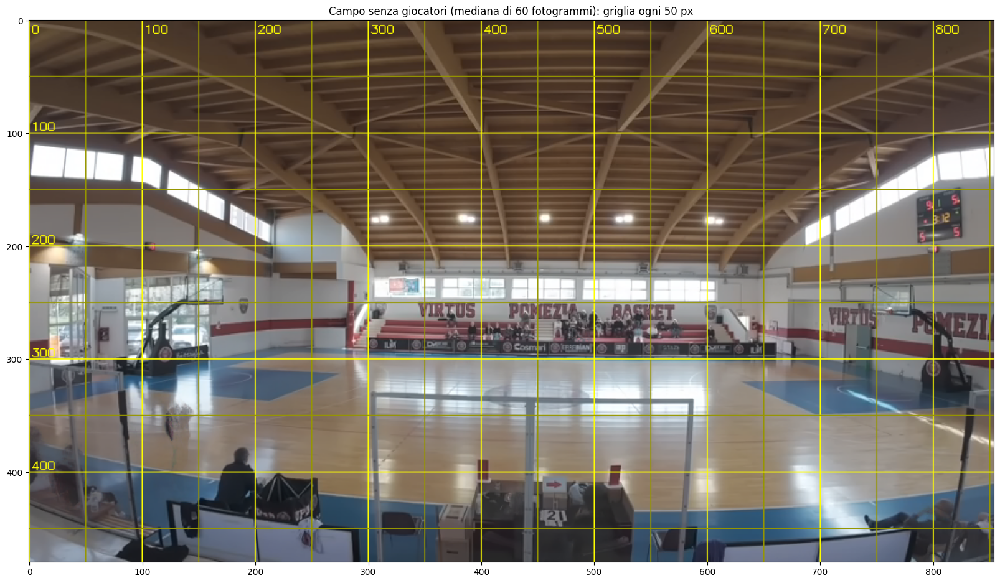

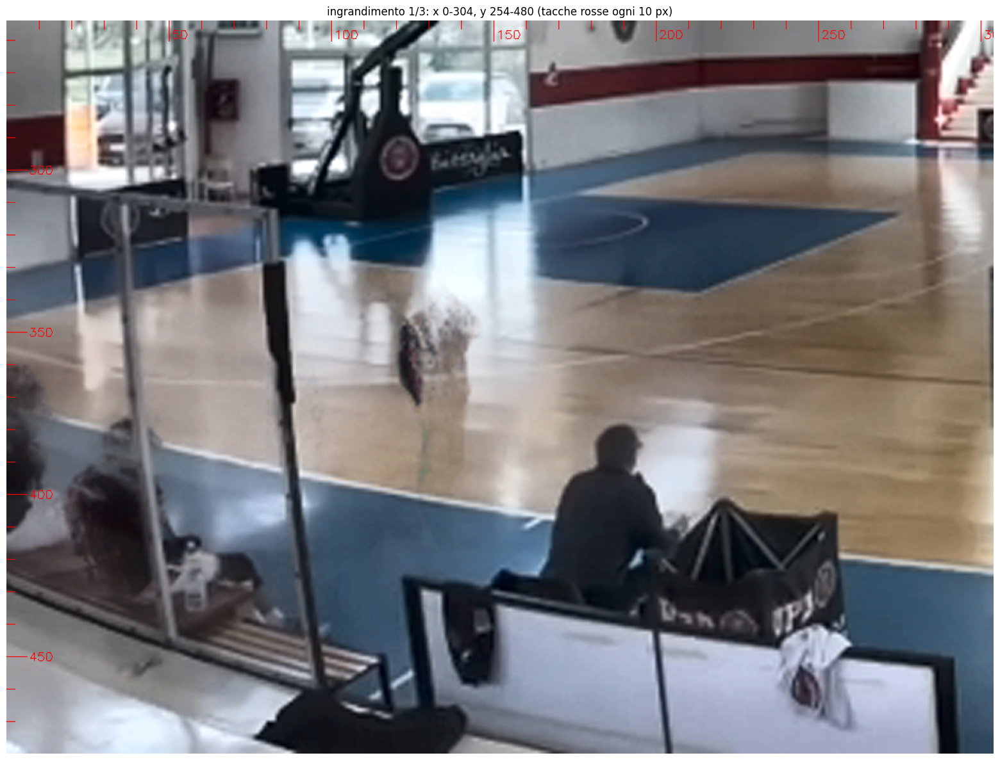

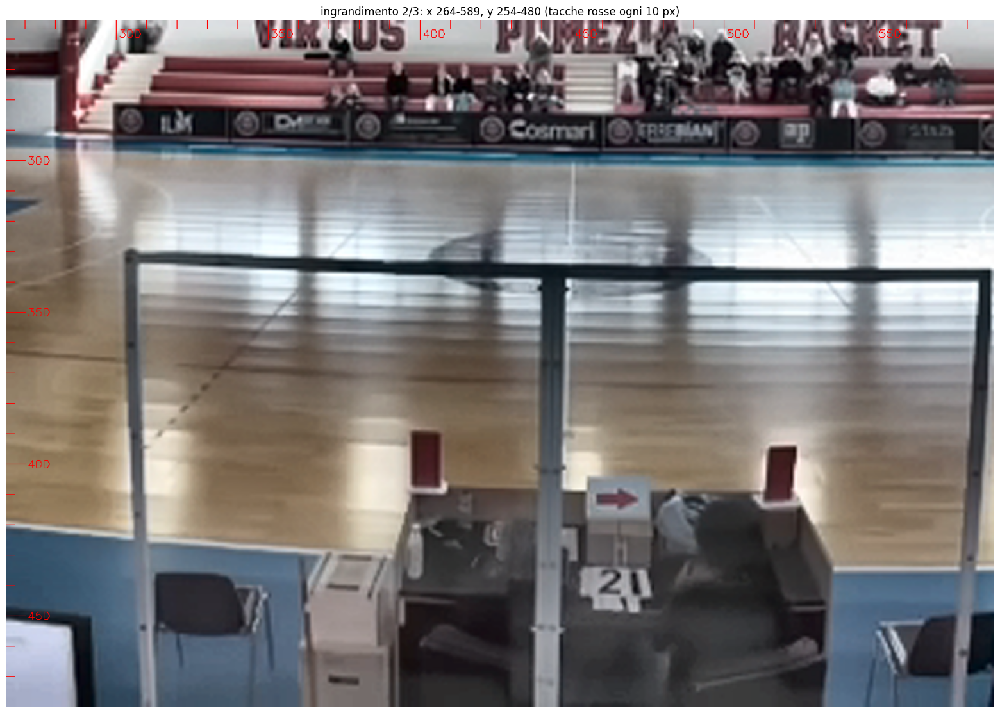

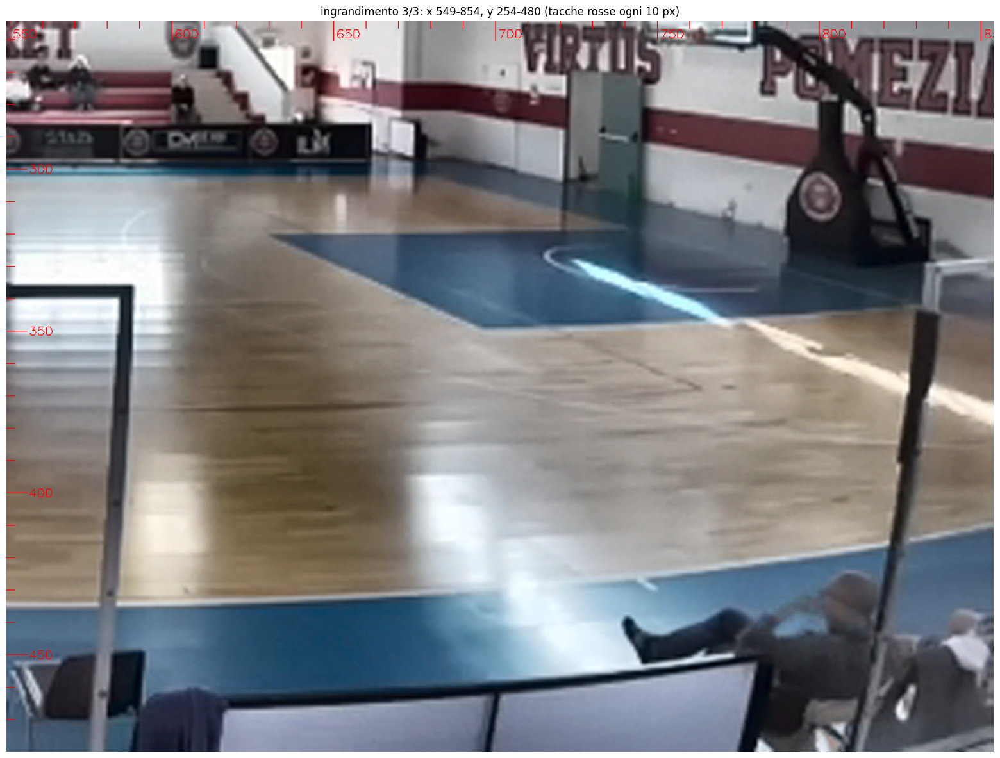

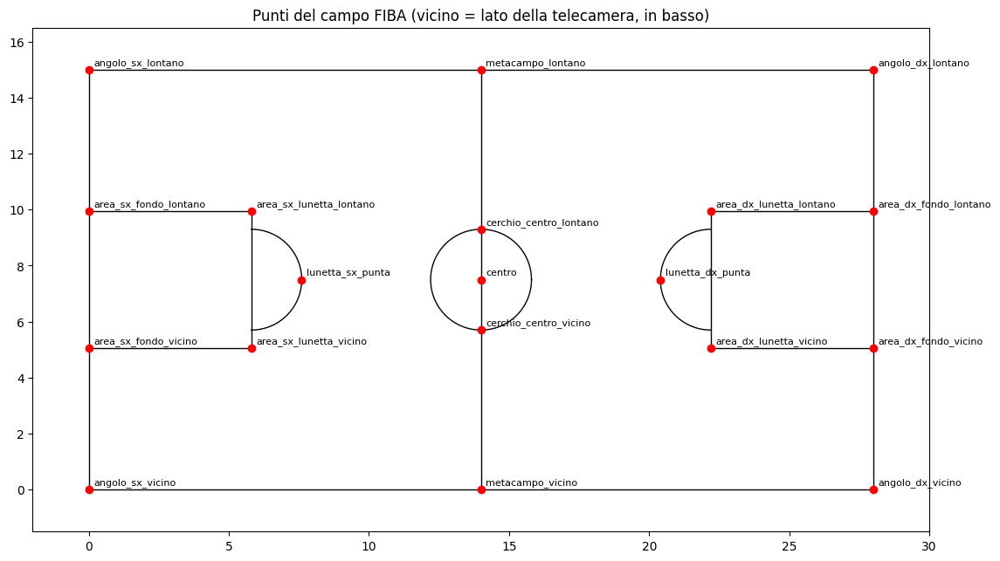

In [5]:
LANDMARKS = {
    'angolo_sx_vicino': (0, 0), 'angolo_sx_lontano': (0, 15), 'angolo_dx_vicino': (28, 0), 'angolo_dx_lontano': (28, 15),
    'metacampo_vicino': (14, 0), 'metacampo_lontano': (14, 15), 'centro': (14, 7.5),
    'cerchio_centro_vicino': (14, 5.7), 'cerchio_centro_lontano': (14, 9.3),
    'area_sx_fondo_vicino': (0, 5.05), 'area_sx_fondo_lontano': (0, 9.95),
    'area_sx_lunetta_vicino': (5.8, 5.05), 'area_sx_lunetta_lontano': (5.8, 9.95), 'lunetta_sx_punta': (7.6, 7.5),
    'area_dx_fondo_vicino': (28, 5.05), 'area_dx_fondo_lontano': (28, 9.95),
    'area_dx_lunetta_vicino': (22.2, 5.05), 'area_dx_lunetta_lontano': (22.2, 9.95), 'lunetta_dx_punta': (20.4, 7.5),
}
# campo "vuoto": mediana di 60 fotogrammi sparsi nella clip (i giocatori si muovono e spariscono, le linee restano)
_fr = [frame_at(int(fi)) for fi in np.linspace(0, N - 1, 60)]
REF = np.median(np.stack([f for f in _fr if f is not None]), axis=0).astype(np.uint8); del _fr
cv2.imwrite(str(RES / 'campo_mediana.png'), REF)
img = REF.copy()
for x in range(0, W, 50):
    cv2.line(img, (x, 0), (x, H), (0, 255, 255) if x % 100 == 0 else (0, 150, 150), 1)
    if x % 100 == 0: cv2.putText(img, str(x), (x + 2, 12), cv2.FONT_HERSHEY_SIMPLEX, .35, (0, 255, 255), 1)
for y in range(0, H, 50):
    cv2.line(img, (0, y), (W, y), (0, 255, 255) if y % 100 == 0 else (0, 150, 150), 1)
    if y % 100 == 0: cv2.putText(img, str(y), (2, y - 2), cv2.FONT_HERSHEY_SIMPLEX, .35, (0, 255, 255), 1)
cv2.imwrite(str(RES / 'calibrazione_griglia.png'), img)
plt.figure(figsize=(20, 11.5)); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title('Campo senza giocatori (mediana di 60 fotogrammi): griglia ogni 50 px'); plt.show()
# ingrandimenti della striscia del campo, con tacche ogni 10 px e contrasto aumentato: qui si leggono le coordinate
y0z, y1z = int(ROI_Y[0] * H) - 10, H
lab = cv2.cvtColor(REF, cv2.COLOR_BGR2LAB); lab[:, :, 0] = cv2.createCLAHE(3.0, (8, 8)).apply(lab[:, :, 0]); REFC = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
for k, (x0z, x1z) in enumerate([(0, W // 3 + 20), (W // 3 - 20, 2 * W // 3 + 20), (2 * W // 3 - 20, W)]):
    z = 4; c = cv2.resize(REFC[y0z:y1z, x0z:x1z], None, fx=z, fy=z, interpolation=cv2.INTER_CUBIC)
    for x in range((x0z // 10 + 1) * 10, x1z, 10):
        X = (x - x0z) * z; cv2.line(c, (X, 0), (X, 10 if x % 50 else 25), (0, 0, 255), 1)
        if x % 50 == 0: cv2.putText(c, str(x), (X + 3, 22), cv2.FONT_HERSHEY_SIMPLEX, .5, (0, 0, 255), 1)
    for y in range((y0z // 10 + 1) * 10, y1z, 10):
        Y = (y - y0z) * z; cv2.line(c, (0, Y), (10 if y % 50 else 25, Y), (0, 0, 255), 1)
        if y % 50 == 0: cv2.putText(c, str(y), (27, Y + 5), cv2.FONT_HERSHEY_SIMPLEX, .5, (0, 0, 255), 1)
    cv2.imwrite(str(RES / f'calibrazione_zoom_{k + 1}.png'), c)
    plt.figure(figsize=(20, 20 * c.shape[0] / c.shape[1])); plt.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB)); plt.axis('off')
    plt.title(f'ingrandimento {k + 1}/3: x {x0z}-{x1z}, y {y0z}-{y1z} (tacche rosse ogni 10 px)'); plt.show()

def court_lines(n=60):                                       # linee del campo FIBA in metri (per disegnarle)
    L = [np.array([[0, 0], [28, 0], [28, 15], [0, 15], [0, 0]]), np.array([[14, 0], [14, 15]])]
    for x0, s in [(0, 1), (28, -1)]:
        L.append(np.array([[x0, 5.05], [x0 + s * 5.8, 5.05], [x0 + s * 5.8, 9.95], [x0, 9.95]]))
        a = np.linspace(-np.pi / 2, np.pi / 2, n); L.append(np.c_[x0 + s * (5.8 + 1.8 * np.cos(a)), 7.5 + 1.8 * np.sin(a)])
    a = np.linspace(0, 2 * np.pi, 2 * n); L.append(np.c_[14 + 1.8 * np.cos(a), 7.5 + 1.8 * np.sin(a)])
    return [l.astype(np.float32) for l in L]
fig, ax = plt.subplots(figsize=(14, 7.5))
for l in court_lines(): ax.plot(l[:, 0], l[:, 1], 'k-', lw=1)
for k, (x, y) in LANDMARKS.items():
    ax.plot(x, y, 'ro'); ax.annotate(k, (x, y), textcoords='offset points', xytext=(4, 4), fontsize=8)
ax.set_aspect('equal'); ax.set_xlim(-2, 30); ax.set_ylim(-1.5, 16.5); ax.set_title('Punti del campo FIBA (vicino = lato della telecamera, in basso)'); plt.show()


  ### B1b. Selezione interattiva dei punti

  È disponibile un'interfaccia Colab per selezionare e correggere manualmente i punti di riferimento del campo.

  Le coordinate vengono salvate nel file `punti_cliccati.json`, in modo da poterle riutilizzare nella calibrazione senza ripetere la selezione.
  


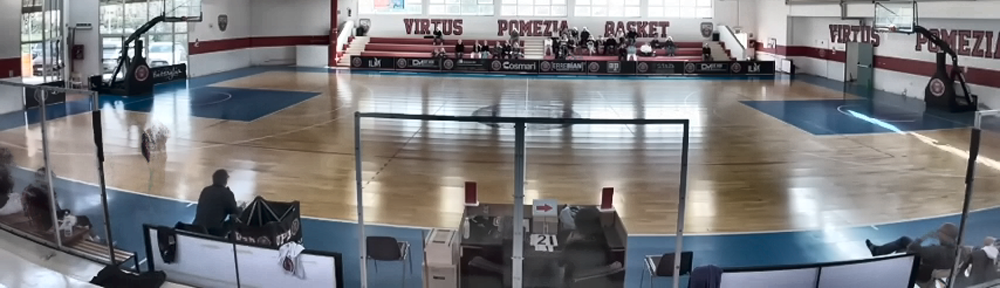

In [6]:
# B1b. Selezione dei punti con un clic (solo Colab; in locale scrivili a mano nella cella B2)
import base64
from IPython.display import HTML, display
PUNTI_FILE = RES / 'punti_cliccati.json'
PUNTI_CLICK = json.loads(PUNTI_FILE.read_text()) if PUNTI_FILE.is_file() else {}
ZC = 3; Y0C = max(0, int(ROI_Y[0] * H) - 30)                 # mostra solo la striscia del campo, ingrandita ZC volte
big = cv2.resize(REFC[Y0C:H], None, fx=ZC, fy=ZC, interpolation=cv2.INTER_CUBIC)
b64 = base64.b64encode(cv2.imencode('.png', big)[1]).decode()

def _save(): PUNTI_FILE.write_text(json.dumps(PUNTI_CLICK, indent=1))
def _add(name, x, y): PUNTI_CLICK[name] = [round(float(x), 1), round(float(y), 1)]; _save()
def _del(name): PUNTI_CLICK.pop(name, None); _save()
if IN_COLAB:
    from google.colab import output
    output.register_callback('dr3.add', _add); output.register_callback('dr3.del', _del)
    opts = ''.join(f'<option value="{k}">{k}</option>' for k in LANDMARKS)
    display(HTML(f"""
<div style="font-family:sans-serif;font-size:14px">
  <b>Punto da cliccare:</b> <select id="nm">{opts}</select>
  <button id="del">Cancella il punto selezionato</button> &nbsp; <span id="st"></span>
  <div style="overflow:auto;max-width:100%;border:1px solid #888;margin-top:6px">
    <canvas id="cv" width="{big.shape[1]}" height="{big.shape[0]}" style="cursor:crosshair"></canvas>
  </div>
</div>
<script>
const Z = {ZC}, Y0 = {Y0C}, pts = {json.dumps(PUNTI_CLICK)};
const sel = document.getElementById('nm'), cv = document.getElementById('cv'), ctx = cv.getContext('2d');
const img = new Image(); img.src = 'data:image/png;base64,{b64}';
function draw() {{
  ctx.drawImage(img, 0, 0);
  for (const [k, p] of Object.entries(pts)) {{
    const X = p[0] * Z, Y = (p[1] - Y0) * Z;
    ctx.strokeStyle = 'red'; ctx.lineWidth = 2; ctx.beginPath(); ctx.arc(X, Y, 7, 0, 2 * Math.PI); ctx.stroke();
    ctx.beginPath(); ctx.moveTo(X - 12, Y); ctx.lineTo(X + 12, Y); ctx.moveTo(X, Y - 12); ctx.lineTo(X, Y + 12); ctx.stroke();
    ctx.fillStyle = 'yellow'; ctx.font = 'bold 15px sans-serif'; ctx.fillText(k, X + 9, Y - 9);
  }}
  for (const o of sel.options) o.text = o.value + (pts[o.value] ? '  ✓' : '');
  document.getElementById('st').textContent = Object.keys(pts).length + ' punti (ne servono almeno 8)';
}}
img.onload = draw;
cv.addEventListener('click', e => {{
  const r = cv.getBoundingClientRect();
  const x = (e.clientX - r.left) * cv.width / r.width / Z, y = (e.clientY - r.top) * cv.height / r.height / Z + Y0;
  const n = sel.value; pts[n] = [Math.round(x * 10) / 10, Math.round(y * 10) / 10];
  google.colab.kernel.invokeFunction('dr3.add', [n, x, y], {{}}); draw();
  if (sel.selectedIndex < sel.options.length - 1) sel.selectedIndex++;
}});
document.getElementById('del').addEventListener('click', () => {{
  delete pts[sel.value]; google.colab.kernel.invokeFunction('dr3.del', [sel.value], {{}}); draw();
}});
</script>"""))
else:
    print('Fuori da Colab il clic interattivo non è disponibile: scrivi i punti a mano nella cella B2.')

Uso i 17 punti cliccati nella cella B1b


,punto,errore_cm_senza_correzione,errore_cm_k1=-0.56
0,angolo_sx_lontano,13.2,25.9
1,angolo_dx_lontano,103.8,48.5
2,metacampo_vicino,55.2,12.1
3,metacampo_lontano,123.5,20.9
4,centro,81.2,11.0
5,cerchio_centro_vicino,75.5,12.0
6,cerchio_centro_lontano,99.4,22.3
7,area_sx_fondo_vicino,199.3,29.2
8,area_sx_fondo_lontano,89.7,18.7
9,area_sx_lunetta_vicino,32.1,19.8


Errore leave-one-out medio: 77.3 cm senza correzione della distorsione -> 19.8 cm con k1 = -0.56 (massimo 48.5 cm)


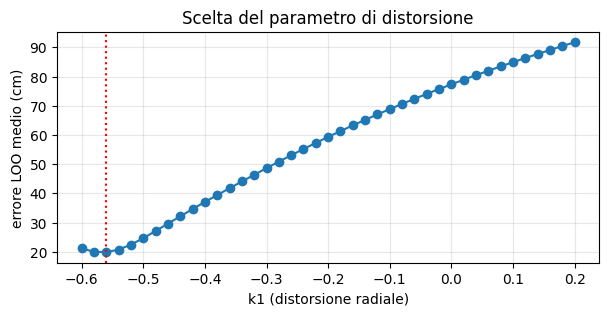

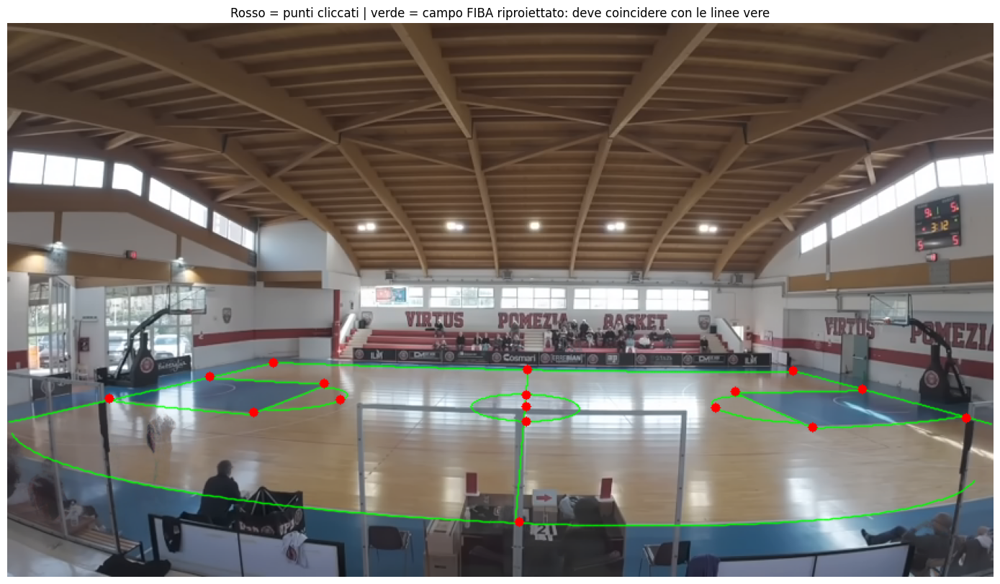

In [7]:
# B2. Calibrazione. Punti: lascia PUNTI vuoto per usare quelli cliccati in B1b, oppure scrivili qui a mano (almeno 8, sparsi)
PUNTI = {
    # 'angolo_sx_vicino': (x, y),
    # 'metacampo_vicino': (x, y),
    # 'area_sx_lunetta_vicino': (x, y),
}
if not PUNTI and (RES / 'punti_cliccati.json').is_file():      # PUNTI vuoto: usa i punti cliccati nella cella B1b
    PUNTI = {k: tuple(v) for k, v in json.loads((RES / 'punti_cliccati.json').read_text()).items()}
    print(f'Uso i {len(PUNTI)} punti cliccati nella cella B1b')
assert len(PUNTI) >= 8, f'Servono almeno 8 punti (ora {len(PUNTI)}): cliccali nella cella B1b o scrivili qui'
assert all(k in LANDMARKS for k in PUNTI), f'Nomi non riconosciuti: {[k for k in PUNTI if k not in LANDMARKS]}'

F = float(W); CX, CY = W / 2, H / 2                         # camera semplificata: distorsione radiale con un solo parametro k1
K = np.array([[F, 0, CX], [0, F, CY], [0, 0, 1]], np.float64)
def undist(px, k1):                                         # pixel della ripresa -> pixel "senza distorsione"
    px = np.asarray(px, np.float64).reshape(-1, 1, 2)
    if k1 == 0: return px.reshape(-1, 2)
    return cv2.undistortPoints(px, K, np.array([k1, 0, 0, 0], np.float64), P=K).reshape(-1, 2)
def dist(pu, k1):                                           # pixel senza distorsione -> pixel della ripresa (per disegnare)
    pu = np.asarray(pu, np.float64).reshape(-1, 2); xn = (pu - [CX, CY]) / F
    r2 = (xn ** 2).sum(1, keepdims=True); return xn * (1 + k1 * r2) * F + [CX, CY]

names = list(PUNTI); IMG = np.float64([PUNTI[k] for k in names]); WORLD = np.float64([LANDMARKS[k] for k in names])
def fit(k1, idx):
    Hm, _ = cv2.findHomography(undist(IMG[idx], k1), WORLD[idx], 0); return Hm
def to_world(px, Hm, k1):
    return cv2.perspectiveTransform(undist(px, k1).reshape(-1, 1, 2), Hm).reshape(-1, 2)
def loo_errors(k1):                                         # leave-one-out: ogni punto stimato con l'omografia calcolata SENZA di lui
    e = []
    for i in range(len(names)):
        idx = [j for j in range(len(names)) if j != i]; Hm = fit(k1, idx)
        e.append(np.linalg.norm(to_world(IMG[i], Hm, k1)[0] - WORLD[i]))
    return np.array(e)

K1S = np.round(np.arange(-0.60, 0.21, 0.02), 2)
loo = {k1: loo_errors(k1).mean() for k1 in K1S}
K1 = min(loo, key=loo.get)
Hm = fit(K1, list(range(len(names)))); Hinv = np.linalg.inv(Hm)
e0, e1 = loo_errors(0.0), loo_errors(K1)
tab = pd.DataFrame({'punto': names, 'errore_cm_senza_correzione': (100 * e0).round(1), f'errore_cm_k1={K1}': (100 * e1).round(1)})
display(tab)
print(f'Errore leave-one-out medio: {100 * e0.mean():.1f} cm senza correzione della distorsione -> {100 * e1.mean():.1f} cm con k1 = {K1} '
      f'(massimo {100 * e1.max():.1f} cm)')
plt.figure(figsize=(7, 3)); plt.plot(list(loo), [100 * v for v in loo.values()], 'o-'); plt.axvline(K1, color='r', ls=':')
plt.xlabel('k1 (distorsione radiale)'); plt.ylabel('errore LOO medio (cm)'); plt.title('Scelta del parametro di distorsione'); plt.grid(alpha=.3); plt.show()

def world_to_px(pw):                                       # metri -> pixel della ripresa; NaN dove il modello non vale
    pu = cv2.perspectiveTransform(np.float64(pw).reshape(-1, 1, 2), Hinv).reshape(-1, 2)
    r2 = (((pu - [CX, CY]) / F) ** 2).sum(1); out = dist(pu, K1)
    out[1 + 3 * K1 * r2 <= 0.05] = np.nan                   # oltre questo raggio la distorsione "si ripiega": punto fuori dal modello
    return out
def in_image(p): return np.isfinite(p).all(1) & (p[:, 0] >= 0) & (p[:, 0] < W) & (p[:, 1] >= 0) & (p[:, 1] < H)
def dense(l, step=0.1):                                     # infittisce una linea: con la distorsione i segmenti diventano curve
    out = [l[0]]
    for a, b in zip(l[:-1], l[1:]):
        n = max(1, int(np.ceil(np.linalg.norm(b - a) / step))); out += [a + (b - a) * t for t in np.linspace(0, 1, n + 1)[1:]]
    return np.array(out)
def draw_court(img, col=(0, 255, 0), th=1):
    for l in court_lines():
        p = world_to_px(dense(l)); ok = np.isfinite(p).all(1) & (np.abs(np.nan_to_num(p)) < 1e4).all(1)
        for run in np.split(np.arange(len(p)), np.where(np.diff(ok.astype(int)) != 0)[0] + 1):
            if ok[run[0]] and len(run) > 1: cv2.polylines(img, [p[run].round().astype(np.int32)], False, col, th, cv2.LINE_AA)
chk = REF.copy(); draw_court(chk)
for k, p in zip(names, IMG): cv2.circle(chk, tuple(int(v) for v in p), 4, (0, 0, 255), -1)
cv2.imwrite(str(RES / 'calibrazione_controllo.png'), chk)
plt.figure(figsize=(18, 10)); plt.imshow(cv2.cvtColor(chk, cv2.COLOR_BGR2RGB)); plt.axis('off')
plt.title('Rosso = punti cliccati | verde = campo FIBA riproiettato: deve coincidere con le linee vere'); plt.show()
CAL = {'k1': K1, 'F': F, 'H_px_to_m': Hm.tolist(), 'punti': {k: list(map(float, PUNTI[k])) for k in names},
       'errore_loo_cm_medio': round(100 * e1.mean(), 1), 'errore_loo_cm_max': round(100 * e1.max(), 1),
       'errore_loo_cm_medio_senza_distorsione': round(100 * e0.mean(), 1), 'n_punti': len(names)}
(RES / 'calibrazione.json').write_text(json.dumps(CAL, indent=1)); tab.to_csv(RES / 'calibrazione_errori.csv', index=False)

## C. Dimensione attesa della palla (dalla calibrazione)

Per ogni punto del campo **inquadrato** (le zone fuori dall'immagine restano bianche) si proietta nell'immagine un segmento di 24 cm (il diametro del pallone) e se ne misura la lunghezza in pixel. È la palla **appoggiata a terra**: in aria, più vicina alla telecamera, è un po' più grande. Per confronto, nei frame NBA di test di E4 la palla era larga in mediana 20,6 px (5°–95° percentile: 15–26 px): il detector non ha mai visto palle molto più piccole.

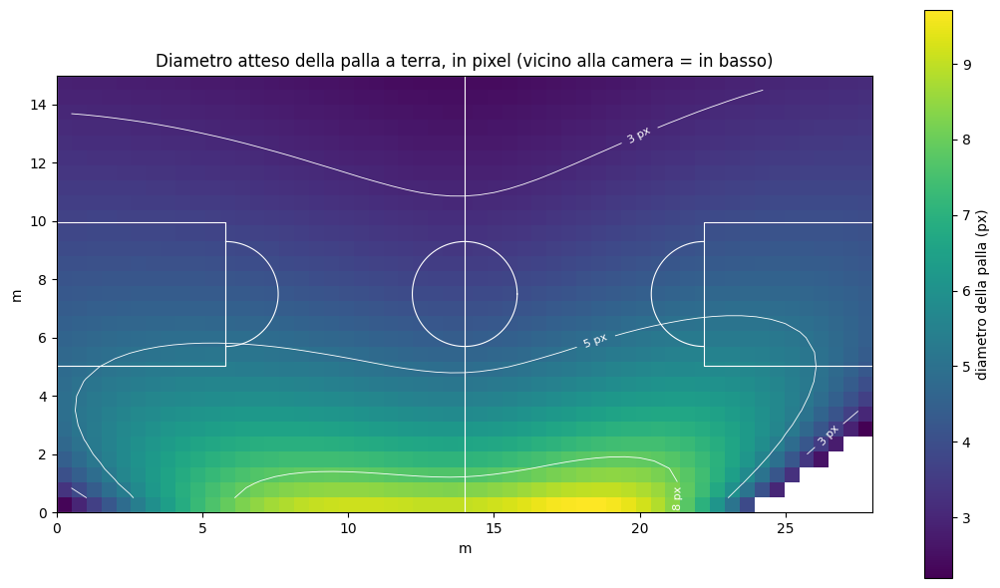

Diametro atteso della palla (px): {'min': 2.2, 'mediana': 4.2, 'max': 9.7, 'quota_campo_inquadrata_%': 98.5, 'quota_campo_sotto_8px_%': 95.6, 'quota_campo_sotto_15px_%': 100.0}


In [8]:
xs, ys = np.arange(0.5, 28, 0.5), np.arange(0.5, 15, 0.5); D = np.zeros((len(ys), len(xs)))
for i, y in enumerate(ys):
    for j, x in enumerate(xs):
        p = world_to_px([[x, y], [x + .24, y], [x, y + .24]])
        D[i, j] = (np.linalg.norm(p[1] - p[0]) + np.linalg.norm(p[2] - p[0])) / 2 if in_image(p).all() else np.nan   # solo la parte di campo inquadrata
fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(D, origin='lower', extent=[0, 28, 0, 15], cmap='viridis'); plt.colorbar(im, label='diametro della palla (px)')
for l in court_lines(): ax.plot(l[:, 0], l[:, 1], 'w-', lw=.8)
cs = ax.contour(xs, ys, D, levels=[3, 5, 8, 12, 15], colors='w', linewidths=.6); ax.clabel(cs, fmt='%d px', fontsize=8)
ax.set_title('Diametro atteso della palla a terra, in pixel (vicino alla camera = in basso)'); ax.set_xlabel('m'); ax.set_ylabel('m')
plt.tight_layout(); plt.savefig(RES / 'dimensione_palla_attesa.png', dpi=160); plt.show()
V_ = D[np.isfinite(D)]
BALL_PX = {'min': round(float(V_.min()), 1), 'mediana': round(float(np.median(V_)), 1), 'max': round(float(V_.max()), 1),
           'quota_campo_inquadrata_%': round(100 * V_.size / D.size, 1),
           'quota_campo_sotto_8px_%': round(100 * float((V_ < 8).mean()), 1), 'quota_campo_sotto_15px_%': round(100 * float((V_ < 15).mean()), 1)}
print('Diametro atteso della palla (px):', BALL_PX)

## D. Giocatori: immagine intera, riquadri ingranditi e unione

- **intera**: il detector vede il fotogramma a 640 px, come nella pipeline NBA. Trova bene i giocatori vicini, perde quelli lontani.
- **riquadri**: la striscia del campo (`ROI_Y`) è divisa in `N_TILES` riquadri sovrapposti, ognuno ingrandito a 1280 px. Trova i giocatori lontani ma produce **pezzi di persona** (solo busto, solo gambe) e falsi positivi (borse, sedie, persone in panchina).
- **unione**: intera + riquadri, togliendo doppioni e pezzi (box contenute per almeno il 70% in una box più grande).
- **filtro altezza**: grazie alla calibrazione si sa quanti pixel per metro ci sono in ogni punto del campo; una box alta molto meno o molto più di una persona in quel punto viene scartata. La scala del filtro si ricava dalle box *intera* (persone intere), non dalla ground truth.

Le scelte per il tracking (`unione` + filtro altezza) sono **fissate prima** della ground truth della sezione K, che poi le misura tutte. Il conteggio delle box in campo qui sotto **non** è una misura di qualità: conta anche i falsi positivi.



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
rapporto altezza box / altezza attesa (box intere in campo): mediana 1.17 su 18 box -> si tengono le box tra 0.58 e 2.10


,tempo_s,in_campo_intera,in_campo_riquadri,in_campo_unione,in_campo_unione_filtrata
0,3.0,1,6,6,5
1,10.7,3,8,5,3
2,18.4,0,8,7,5
3,26.1,1,2,2,2
4,33.9,2,4,6,5
5,41.6,1,3,4,4
6,49.3,4,9,9,8
7,57.0,6,9,8,8


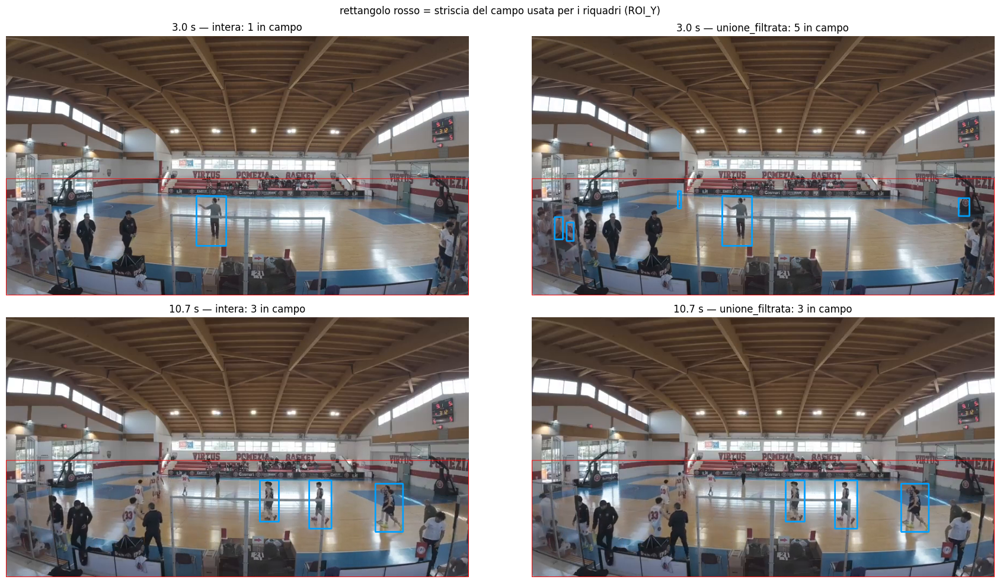

Modalità usata per il tracking (fissata prima della ground truth): unione, filtro altezza = True
Il numero di box "in campo" NON è una misura di qualità (conta anche i falsi positivi): la misura vera è la sezione K.


In [9]:
from ultralytics import YOLO
det = YOLO(str(PLAYER_WEIGHTS)); PL = [i for i, n in det.names.items() if n.startswith('player')] or None
DET_MODE, FILTRO_ALTEZZA = 'unione', True       # scelti PRIMA della ground truth (sezione K), guardando i riquadri qui sotto
H_PERSONA = 1.85                                 # altezza tipica di un giocatore (m) per il filtro di plausibilità

def nms(boxes, scores, thr=0.5):
    order, keep = np.argsort(-scores), []
    while len(order):
        i = order[0]; keep.append(i); rest = order[1:]
        if not len(rest): break
        tl = np.maximum(boxes[i, :2], boxes[rest, :2]); br = np.minimum(boxes[i, 2:], boxes[rest, 2:])
        inter = np.prod(np.clip(br - tl, 0, None), axis=1); ar = lambda b: np.prod(b[..., 2:] - b[..., :2], axis=-1)
        order = rest[inter / (ar(boxes[i]) + ar(boxes[rest]) - inter + 1e-9) <= thr]
    return np.array(keep, int)

def drop_fragments(a, thr=0.7):                  # toglie i "pezzi" di persona: box contenute per >= 70% in una box più grande
    if not len(a): return a
    a = a[nms(a[:, :4], a[:, 4])]; keep = []
    for i in np.argsort(-np.prod(a[:, 2:4] - a[:, :2], 1)):
        b = a[i, :4]; ab = np.prod(b[2:] - b[:2]) + 1e-9
        if any(np.prod(np.clip(np.minimum(b[2:], a[j, 2:4]) - np.maximum(b[:2], a[j, :2]), 0, None)) / ab >= thr for j in keep): continue
        keep.append(i)
    return a[sorted(keep)]

def detect(f, mode):
    if mode == 'intera':                         # come la pipeline NBA: fotogramma intero a 640 px
        r = det.predict(f, conf=DET_CONF, imgsz=640, classes=PL, verbose=False)[0]
        return np.c_[r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()].reshape(-1, 5)
    if mode == 'unione':                         # intera + riquadri, senza doppioni e senza pezzi di persona
        return drop_fragments(np.concatenate([detect(f, 'intera'), detect(f, 'riquadri')]))
    y0, y1 = int(ROI_Y[0] * H), int(ROI_Y[1] * H); tw = W / (N_TILES - (N_TILES - 1) * TILE_OVERLAP); out = []
    for k in range(N_TILES):                     # riquadri della striscia del campo, ingranditi a 1280 px
        x0 = int(round(k * tw * (1 - TILE_OVERLAP))); x1 = min(W, int(round(x0 + tw)))
        tile = f[y0:y1, x0:x1]; s = 1280 / tile.shape[1]
        r = det.predict(cv2.resize(tile, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC), conf=DET_CONF, imgsz=1280, classes=PL, verbose=False)[0]
        out.append(np.c_[r.boxes.xyxy.cpu().numpy() / s + [x0, y0, x0, y0], r.boxes.conf.cpu().numpy()])
    a = np.concatenate(out) if out else np.zeros((0, 5))
    return a[nms(a[:, :4], a[:, 4])] if len(a) else a

def in_mask(x, y): return any(cv2.pointPolygonTest(np.int32(m), (float(x), float(y)), False) >= 0 for m in MASKS)
def feet_world(b): return to_world(np.c_[(b[:, 0] + b[:, 2]) / 2, b[:, 3]], Hm, K1) if len(b) else np.zeros((0, 2))
def in_court(pw, m=0.5): return (pw[:, 0] > -m) & (pw[:, 0] < COURT_L + m) & (pw[:, 1] > -m) & (pw[:, 1] < COURT_W + m)
def h_ratio(b):                                  # altezza della box / altezza attesa di una persona in quel punto del campo
    if not len(b): return np.zeros(0)
    pw = feet_world(b); dx = np.array([[0.5, 0.0]])
    s = np.linalg.norm(world_to_px(pw + dx) - world_to_px(pw - dx), axis=1)      # pixel per metro ai piedi della persona
    return (b[:, 3] - b[:, 1]) / (H_PERSONA * s + 1e-9)

CHECK_T = np.linspace(3, CLIP_S - 3, 8).round(1)
# scala del filtro: mediana del rapporto sulle box "intera" in campo (persone intere, viste bene): non usa la ground truth
_r = []
for t in CHECK_T:
    b = detect(frame_at(int(t * FPS)), 'intera')
    if len(b): _r += list(h_ratio(b)[in_court(feet_world(b))])
H_SCALE = float(np.nanmedian(_r)) if len(_r) >= 3 else 1.0
H_RANGE = (0.5 * H_SCALE, 1.8 * H_SCALE)
print(f'rapporto altezza box / altezza attesa (box intere in campo): mediana {H_SCALE:.2f} su {len(_r)} box -> si tengono le box tra {H_RANGE[0]:.2f} e {H_RANGE[1]:.2f}')
def plausible(b): r = h_ratio(b); return np.isfinite(r) & (r >= H_RANGE[0]) & (r <= H_RANGE[1])
def keep_players(b, campo=True, altezza=True, masch=True):     # filtri a valle della detection
    if not len(b): return b
    k = np.ones(len(b), bool)
    if campo: k &= in_court(feet_world(b))
    if altezza: k &= plausible(b)
    if masch and MASKS: k &= np.array([not in_mask((x1 + x2) / 2, y2) for x1, y1, x2, y2 in b[:, :4]], bool)
    return b[k]

VERI = {}                     # facoltativo: {tempo_s: giocatori in campo contati a mano}, per esempio {3.0: 10, 10.7: 10}
MODI = {'intera': ('intera', False), 'riquadri': ('riquadri', False), 'unione': ('unione', False), 'unione_filtrata': ('unione', True)}
rows, show = [], []
for t in CHECK_T:
    f = frame_at(int(t * FPS)); r = {'tempo_s': t}; cache_m = {}
    for name, (mode, alt) in MODI.items():
        if mode not in cache_m: cache_m[mode] = detect(f, mode)
        b = keep_players(cache_m[mode], campo=True, altezza=alt); r[f'in_campo_{name}'] = len(b)
        if t in CHECK_T[:2] and name in ('intera', 'unione_filtrata'): show.append((t, name, f.copy(), b))
    if t in VERI: r['veri'] = VERI[t]
    rows.append(r)
cmp_det = pd.DataFrame(rows)
if 'veri' in cmp_det:
    for name in MODI: cmp_det[f'recall_{name}'] = (np.minimum(cmp_det[f'in_campo_{name}'], cmp_det.veri) / cmp_det.veri).round(2)
display(cmp_det); cmp_det.to_csv(RES / 'giocatori_modalita.csv', index=False)
fig, ax = plt.subplots(2, 2, figsize=(18, 10))
for a_, (t, name, f, b) in zip(ax.ravel(), show):
    for x1, y1, x2, y2, _ in b.astype(int): cv2.rectangle(f, (x1, y1), (x2, y2), (255, 160, 0), 2)
    cv2.rectangle(f, (0, int(ROI_Y[0] * H)), (W - 1, int(ROI_Y[1] * H) - 1), (0, 0, 255), 1)
    a_.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); a_.set_title(f'{t} s — {name}: {len(b)} in campo'); a_.axis('off')
plt.suptitle('rettangolo rosso = striscia del campo usata per i riquadri (ROI_Y)'); plt.tight_layout(); plt.show()
print(f'Modalità usata per il tracking (fissata prima della ground truth): {DET_MODE}, filtro altezza = {FILTRO_ALTEZZA}')
print('Il numero di box "in campo" NON è una misura di qualità (conta anche i falsi positivi): la misura vera è la sezione K.')

## E. Tracking (BoT-SORT, parametri di default) e posizioni in metri

In [10]:
import supervision as sv, trackers as T, importlib
BoT = getattr(T, 'BoTSORTTracker', None) or importlib.import_module('trackers.core.botsort.tracker').BoTSORTTracker
trk = BoT(frame_rate=FPS)                        # parametri di default, come nei notebook 11 e 18
cache = RES / f'tracks_{DET_MODE}{"_alt" if FILTRO_ALTEZZA else ""}.csv'
if cache.is_file():
    tracks = pd.read_csv(cache); print('[cache] tracce lette da', cache.name)
else:
    rows = []; cap = cv2.VideoCapture(str(CLIP)); t0 = time.time()
    for fi in tqdm(range(N), desc=f'detection ({DET_MODE}) e tracking'):
        ok, f = cap.read()
        if not ok: break
        b = keep_players(detect(f, DET_MODE), campo=False, altezza=FILTRO_ALTEZZA)   # il filtro campo si applica dopo, sulla traccia intera
        d = sv.Detections(xyxy=b[:, :4].astype(np.float32), confidence=b[:, 4].astype(np.float32), class_id=np.zeros(len(b), int))
        tr = trk.update(d, frame=f)
        for (x1, y1, x2, y2), tid in zip(tr.xyxy, tr.tracker_id):
            if tid is not None and tid >= 0: rows.append((fi, int(tid), x1, y1, x2, y2))
    cap.release(); print(f'{N / (time.time() - t0):.1f} frame/s')
    tracks = pd.DataFrame(rows, columns=['frame', 'track_id', 'x1', 'y1', 'x2', 'y2']); tracks.to_csv(cache, index=False)
pw = feet_world(tracks[['x1', 'y1', 'x2', 'y2']].values); tracks['x_m'], tracks['y_m'] = pw[:, 0], pw[:, 1]
out = ~in_court(pw, OUT_MARGIN_M); frac = pd.Series(out).groupby(tracks.track_id.values).mean()
fuori = frac[frac >= 0.6].index
tracks = tracks[~tracks.track_id.isin(fuori)].reset_index(drop=True)
print(f'tracce: {tracks.track_id.nunique()} (eliminate {len(fuori)} persone fuori dal campo) | righe: {len(tracks)}')

[cache] tracce lette da tracks_unione_alt.csv
tracce: 122 (eliminate 3 persone fuori dal campo) | righe: 4951


## E2. Post-processing: unione dei frammenti di traccia

A 480p i giocatori lontani vengono rilevati a intermittenza: BoT-SORT perde la traccia dopo circa un secondo e, quando il giocatore ricompare, gli dà un **ID nuovo**. Il risultato sono tante tracce corte (frammentazione). Grazie alla calibrazione si conoscono le posizioni in metri, quindi si possono **ricucire offline**: la traccia B continua la traccia A se B inizia entro `GAP_MAX_S` secondi dalla fine di A e in un punto raggiungibile correndo (al massimo `V_LINK` m/s, più 1 m di tolleranza). Si uniscono per prime le coppie più compatibili; ogni traccia ha al massimo un successore e un predecessore. È una versione semplice dell'associazione offline dei tracklet (GTA) indicata negli sviluppi futuri. I parametri sono fissati a priori da valori fisici, non tarati sui risultati.

In [11]:
GAP_MAX_S, V_LINK, R0_M, OVERLAP_MAX = 2.0, 7.0, 1.0, 5      # secondi, m/s, metri, frame di sovrapposizione tollerati
def stitch(t):
    s = t.sort_values('frame').groupby('track_id').agg(f0=('frame', 'min'), f1=('frame', 'max'))
    ends = {tid: g.sort_values('frame') for tid, g in t.groupby('track_id')}
    pos0 = {tid: g[['x_m', 'y_m']].head(5).median().values for tid, g in ends.items()}
    pos1 = {tid: g[['x_m', 'y_m']].tail(5).median().values for tid, g in ends.items()}
    cand = []
    for a, ra in s.iterrows():
        for b, rb in s[(s.f0 > ra.f1 - OVERLAP_MAX) & (s.f0 <= ra.f1 + GAP_MAX_S * FPS) & (s.f1 > ra.f1)].iterrows():
            if a == b: continue
            gap = max(0.0, (rb.f0 - ra.f1) / FPS); d = float(np.linalg.norm(pos0[b] - pos1[a])); lim = R0_M + V_LINK * gap
            if d <= lim: cand.append((d / lim, a, b))
    nxt, prv = {}, {}
    for _, a, b in sorted(cand):
        if a in nxt or b in prv: continue
        nxt[a], prv[b] = b, a
    root = {}
    for tid in s.index:
        r = tid
        while r in prv: r = prv[r]
        root[tid] = r
    out = t.copy(); out['track_id'] = out.track_id.map(root)
    return out.sort_values(['track_id', 'frame']).drop_duplicates(['track_id', 'frame'], keep='first'), len(nxt)

def frag_stats(t):
    d = t.groupby('track_id').frame.agg(lambda f: (f.max() - f.min() + 1) / FPS)
    return {'tracce': int(t.track_id.nunique()), 'durata_media_s': round(float(d.mean()), 1),
            'tracce_oltre_10s': int((d >= 10).sum()), 'tracce_oltre_metà_clip': int((d >= CLIP_S / 2).sum())}
prima = frag_stats(tracks)
if 'track_id_orig' not in tracks: tracks['track_id_orig'] = tracks.track_id
tracks, n_link = stitch(tracks)
dopo = frag_stats(tracks)
FRAG = pd.DataFrame({'prima': prima, 'dopo': dopo}); display(FRAG); FRAG.to_csv(RES / 'frammentazione_tracce.csv')
print(f'collegamenti fatti: {n_link}')

,prima,dopo
tracce,122.0,37.0
durata_media_s,1.7,8.5
tracce_oltre_10s,2.0,14.0
tracce_oltre_metà_clip,0.0,0.0


collegamenti fatti: 85


## F. Squadre dal colore della maglia

colori maglia:   0%|          | 0/1800 [00:00<?, ?it/s]

tracce per squadra (0 = maglia scura, 1 = chiara, -1 = altro/arbitro): {-1: 7, 0: 14, 1: 16}


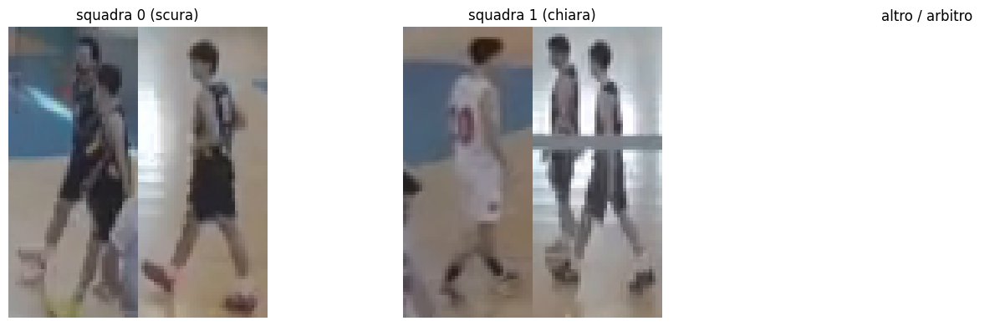

In [12]:
from sklearn.cluster import KMeans
feat = {}; step = 5; cap = cv2.VideoCapture(str(CLIP)); by_f = dict(tuple(tracks[tracks.frame % step == 0].groupby('frame')))
for fi in tqdm(range(N), desc='colori maglia'):
    ok, f = cap.read()
    if not ok: break
    if fi not in by_f: continue
    lab = cv2.cvtColor(f, cv2.COLOR_BGR2LAB)
    for r in by_f[fi].itertuples():
        h_, w_ = r.y2 - r.y1, r.x2 - r.x1
        y0, y1 = int(r.y1 + .15 * h_), int(r.y1 + .5 * h_); x0, x1 = int(r.x1 + .25 * w_), int(r.x2 - .25 * w_)   # busto
        if y1 - y0 < 3 or x1 - x0 < 2: continue
        feat.setdefault(r.track_id, []).append(np.median(lab[max(0, y0):y1, max(0, x0):x1].reshape(-1, 3), 0))
cap.release()
ids = [t for t, v in feat.items() if len(v) >= 3]; X = np.array([np.median(feat[t], 0) for t in ids])
km = KMeans(3, n_init=10, random_state=0).fit(X)
size = pd.Series(km.labels_).value_counts(); team_cl = list(size.index[:2]); other = list(size.index[2:])
lum = {c: km.cluster_centers_[c][0] for c in team_cl}; dark, light = sorted(team_cl, key=lum.get)
team_of = {t: (0 if c == dark else 1 if c == light else -1) for t, c in zip(ids, km.labels_)}
tracks['team'] = tracks.track_id.map(team_of).fillna(-1).astype(int)
print('tracce per squadra (0 = maglia scura, 1 = chiara, -1 = altro/arbitro):', tracks.groupby('team').track_id.nunique().to_dict())
# controllo visivo: alcune figurine per gruppo
f = frame_at(int(T_REF * FPS)); g = tracks[tracks.frame == int(T_REF * FPS)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, tm, name in zip(ax, [0, 1, -1], ['squadra 0 (scura)', 'squadra 1 (chiara)', 'altro / arbitro']):
    crops = [cv2.resize(f[int(r.y1):int(r.y2), int(r.x1):int(r.x2)], (40, 90)) for r in g[g.team == tm].itertuples() if r.y2 - r.y1 > 5 and r.x2 - r.x1 > 3]
    a_.imshow(cv2.cvtColor(np.hstack(crops), cv2.COLOR_BGR2RGB) if crops else np.ones((90, 40, 3))); a_.set_title(name); a_.axis('off')
plt.tight_layout(); plt.savefig(RES / 'controllo_squadre.png', dpi=130); plt.show()

## G. Mappa 2D, heatmap, distanze e velocità

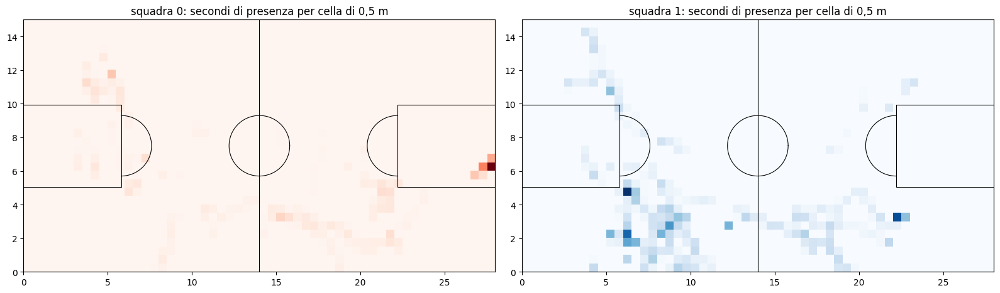

,track_id,squadra,durata_s,distanza_m,vel_media_m_s,vel_max_0.5s_m_s
16,79,0,13.3,55.8,4.21,6.55
15,76,0,15.5,27.2,1.75,6.05
1,2,0,8.6,25.3,2.95,3.37
11,61,0,6.7,18.9,2.84,5.51
3,7,0,6.9,15.0,2.17,2.74
19,104,0,7.6,14.0,1.85,3.02
21,114,0,2.3,9.5,4.15,1.69
7,17,0,19.8,5.1,0.26,2.26
20,113,0,5.6,4.6,0.82,2.05
13,72,0,2.6,4.5,1.75,3.19


velocità massima mediana: 3.2350000000000003 m/s | tracce: 22


In [13]:
def interp(t):
    out = []
    for tid, g in t.groupby('track_id'):
        g = g.set_index('frame').sort_index(); full = g.reindex(range(g.index.min(), g.index.max() + 1))
        miss = full.x_m.isna(); run = (~miss).cumsum()
        full[['x_m', 'y_m']] = full[['x_m', 'y_m']].interpolate(limit_area='inside')
        full = full[~miss | (miss.groupby(run).transform('sum') <= INTERP_MAX_GAP)]
        full['track_id'] = tid; full['team'] = g.team.iloc[0]; out.append(full.reset_index())
    return pd.concat(out, ignore_index=True)
P = interp(tracks[['frame', 'track_id', 'x_m', 'y_m', 'team']])
P[['xs', 'ys']] = P.groupby('track_id')[['x_m', 'y_m']].transform(lambda s: s.rolling(15, center=True, min_periods=1).median())

# heatmap per squadra
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a_, tm, cmap in zip(ax, [0, 1], ['Reds', 'Blues']):
    q = P[P.team == tm]; Hh, _, _ = np.histogram2d(q['xs'], q['ys'], bins=[56, 30], range=[[0, 28], [0, 15]])
    a_.imshow(Hh.T / FPS, origin='lower', extent=[0, 28, 0, 15], cmap=cmap)
    for l in court_lines(): a_.plot(l[:, 0], l[:, 1], 'k-', lw=.8)
    a_.set_title(f'squadra {tm}: secondi di presenza per cella di 0,5 m'); a_.set_aspect('equal')
plt.tight_layout(); plt.savefig(RES / 'heatmap_squadre.png', dpi=160); plt.show()

# distanze e velocità (tracce di almeno MIN_TRACK_S secondi; campioni ogni 0,2 s; salti oltre MAX_SPEED scartati)
st = []; k = max(1, int(round(0.2 * FPS)))
for tid, g in P.groupby('track_id'):
    if len(g) < MIN_TRACK_S * FPS or g.team.iloc[0] < 0: continue
    s = g.iloc[::k]; d = np.hypot(np.diff(s['xs']), np.diff(s['ys'])); dt = np.diff(s.frame) / FPS; v = d / np.maximum(dt, 1e-6)
    ok = v <= MAX_SPEED; dist_m = float(d[ok].sum())
    vw = pd.Series(v[ok]).rolling(max(1, int(round(0.5 / 0.2))), min_periods=1).mean()
    st.append({'track_id': tid, 'squadra': int(g.team.iloc[0]), 'durata_s': round(len(g) / FPS, 1), 'distanza_m': round(dist_m, 1),
               'vel_media_m_s': round(dist_m / (len(g) / FPS), 2), 'vel_max_0.5s_m_s': round(float(vw.max()), 2) if len(vw) else np.nan})
stats = pd.DataFrame(st).sort_values(['squadra', 'distanza_m'], ascending=[True, False]); stats.to_csv(RES / 'distanze_velocita.csv', index=False)
display(stats)
print('velocità massima mediana:', stats['vel_max_0.5s_m_s'].median(), 'm/s | tracce:', len(stats))

## H. Video dimostrativo: box per squadra e mini-mappa

In [14]:
VIDEO_S = 20                                     # secondi di video
S_MAP, PAD = 14, 12                              # pixel per metro della mini-mappa
mw, mh = int(COURT_L * S_MAP) + 2 * PAD, int(COURT_W * S_MAP) + 2 * PAD
base = np.full((mh, mw, 3), (200, 225, 240), np.uint8)
for l in court_lines(): cv2.polylines(base, [(l * S_MAP + PAD).astype(np.int32)[:, ::1]], False, (60, 60, 60), 1, cv2.LINE_AA)
base = base[::-1].copy()                         # y verso l'alto: lato vicino alla camera in basso, come nel video
COL = {0: (40, 40, 200), 1: (230, 230, 230), -1: (120, 120, 120)}
by_f = dict(tuple(tracks.groupby('frame'))); byP = dict(tuple(P.groupby('frame')))
out_v = RES / 'demo.mp4'; vw_ = cv2.VideoWriter(str(out_v), cv2.VideoWriter_fourcc(*'mp4v'), FPS, (W, H + mh))
cap = cv2.VideoCapture(str(CLIP))
for fi in tqdm(range(min(N, int(VIDEO_S * FPS))), desc='video'):
    ok, f = cap.read()
    if not ok: break
    for r in by_f.get(fi, pd.DataFrame()).itertuples():
        cv2.rectangle(f, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), COL.get(int(getattr(r, 'team', -1)), (0, 255, 255)), 2)
    m = base.copy()
    for r in byP.get(fi, pd.DataFrame()).itertuples():
        if np.isnan(r.xs): continue
        x, y = int(r.xs * S_MAP + PAD), mh - 1 - int(r.ys * S_MAP + PAD)
        cv2.circle(m, (x, y), 6, COL.get(int(getattr(r, 'team', -1)), (0, 255, 255)), -1); cv2.circle(m, (x, y), 6, (0, 0, 0), 1)
    canvas = np.zeros((H + mh, W, 3), np.uint8); canvas[:H] = f; x0 = (W - mw) // 2
    canvas[H:, max(0, x0):max(0, x0) + min(mw, W)] = m[:, :min(mw, W)]
    vw_.write(canvas)
cap.release(); vw_.release(); print('Video salvato:', out_v)

video:   0%|          | 0/600 [00:00<?, ?it/s]

Video salvato: /content/drive/MyDrive/Tesi_Basket/events_amatoriali/dr3_c1/demo.mp4


## I. Palla: in quanti frame viene trovata?

palla:   0%|          | 0/360 [00:00<?, ?it/s]

ball_detector.pt: palla trovata (conf >= 0,25) nel 14.7% dei frame analizzati (uno ogni 5)


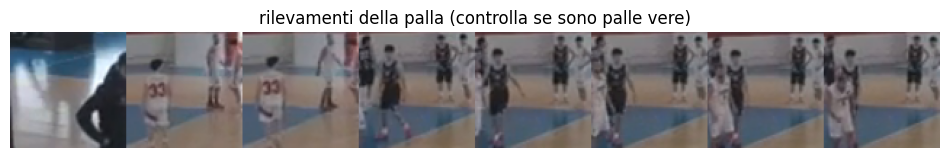

In [15]:
ball = YOLO(str(BALL_WEIGHTS)); found, crops = [], []
for fi in tqdm(range(0, N, 5), desc='palla'):
    f = frame_at(fi); r = ball.predict(f, conf=0.25, imgsz=1280, verbose=False)[0]; found.append(len(r.boxes) > 0)
    for x1, y1, x2, y2 in r.boxes.xyxy.cpu().numpy().astype(int)[:1]:
        if len(crops) < 8: crops.append(cv2.resize(f[max(0, y1 - 20):y2 + 20, max(0, x1 - 20):x2 + 20], (80, 80)))
BALL_RATE = round(100 * float(np.mean(found)), 1)
print(f'{BALL_WEIGHTS.name}: palla trovata (conf >= 0,25) nel {BALL_RATE}% dei frame analizzati (uno ogni 5)')
if crops:
    plt.figure(figsize=(12, 2)); plt.imshow(cv2.cvtColor(np.hstack(crops), cv2.COLOR_BGR2RGB)); plt.axis('off')
    plt.title('rilevamenti della palla (controlla se sono palle vere)'); plt.show()

## J. Riepilogo per la tesi

In [16]:
summary = {'clip': CLIP_NAME, 'video': SRC.name, 'inizio_nel_video': CLIP_START, 'risoluzione': f'{W}x{H}', 'fps': FPS,
           'calibrazione': {k: CAL[k] for k in ['n_punti', 'k1', 'errore_loo_cm_medio', 'errore_loo_cm_max', 'errore_loo_cm_medio_senza_distorsione']},
           'diametro_palla_atteso_px': BALL_PX, 'palla_trovata_%': BALL_RATE, 'detector_palla': BALL_WEIGHTS.name,
           'giocatori_in_campo_medi': {m: round(float(cmp_det[f'in_campo_{m}'].mean()), 1) for m in MODI},
           'modalita_detection': DET_MODE, 'filtro_altezza': FILTRO_ALTEZZA, 'scala_filtro_altezza': round(H_SCALE, 2), 'tracce_squadra': tracks.groupby('team').track_id.nunique().to_dict(),
           'vel_max_mediana_m_s': float(stats['vel_max_0.5s_m_s'].median()) if len(stats) else None,
           'frammentazione_tracce': FRAG.to_dict()}
if 'veri' in cmp_det: summary['recall_giocatori'] = {m: round(float(cmp_det[f'recall_{m}'].mean()), 2) for m in MODI}
(RES / 'riepilogo.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=str))
print(json.dumps(summary, indent=2, ensure_ascii=False, default=str))

{
  "clip": "dr3_c1",
  "video": "pomezia_aprilia_dr3.mp4",
  "inizio_nel_video": "15:20",
  "risoluzione": "854x480",
  "fps": 30.0,
  "calibrazione": {
    "n_punti": 17,
    "k1": -0.56,
    "errore_loo_cm_medio": 19.8,
    "errore_loo_cm_max": 48.5,
    "errore_loo_cm_medio_senza_distorsione": 77.3
  },
  "diametro_palla_atteso_px": {
    "min": 2.2,
    "mediana": 4.2,
    "max": 9.7,
    "quota_campo_inquadrata_%": 98.5,
    "quota_campo_sotto_8px_%": 95.6,
    "quota_campo_sotto_15px_%": 100.0
  },
  "palla_trovata_%": 14.7,
  "detector_palla": "ball_detector.pt",
  "giocatori_in_campo_medi": {
    "intera": 2.2,
    "riquadri": 6.1,
    "unione": 5.9,
    "unione_filtrata": 5.0
  },
  "modalita_detection": "unione",
  "filtro_altezza": true,
  "scala_filtro_altezza": 1.17,
  "tracce_squadra": {
    "-1": 7,
    "0": 14,
    "1": 16
  },
  "vel_max_mediana_m_s": 3.2350000000000003,
  "frammentazione_tracce": {
    "prima": {
      "tracce": 122.0,
      "durata_media_s": 1.7,
  

## K. Ground truth su frame sparsi: ablation, recall per altezza, palla e requisiti

La clip serve a mostrare la pipeline; **i numeri** si misurano su ~50 fotogrammi presi a intervalli regolari da **tutta la partita** (primo e secondo tempo, entrambi i lati del campo). La calibrazione della sezione B vale per tutti, perché la camera è fissa.

**K1** estrae i fotogrammi, **senza pre-annotazione** (la ground truth non deve dipendere dal modello).
 **K2** misura:

| Misura | A cosa serve |
|---|---|
| Precisione e recall dei giocatori per configurazione (ablation) | quanto recupera ogni adattamento rispetto alla pipeline NBA invariata |
| Recall in funzione dell'altezza della box | **requisito**: quanti pixel deve essere alto un giocatore |
| Diametro reale della palla e quota trovata | **requisito**: quanti pixel deve misurare la palla |
| Movimento della camera, fps, errore di calibrazione | altri requisiti |

Regola di metodo: gli adattamenti (riquadri, filtro campo, maschere) sono decisi **prima** di vedere K2 e non vengono ritoccati dopo.

Fotogrammi già estratti: non li rigenero (la ground truth fa riferimento a questi file).
50 fotogrammi | zip da caricare su Roboflow: /content/drive/MyDrive/Tesi_Basket/datasets/dr3_gt_da_annotare.zip


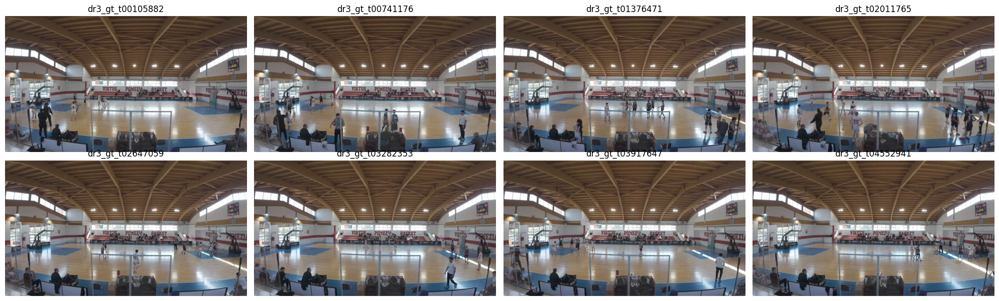

In [17]:
# K1. Estrazione dei fotogrammi per la ground truth
import zipfile
PARTITA = ('0:00:00', '1:30:00')     # <-- DA COMPILARE: inizio e fine della partita nel video (intervallo compreso: i frame non di gioco li cancelli tu)
N_GT = 50                            # ne estrae 50: cancellerai quelli non di gioco (time-out, intervallo), ne restano ~40
GT_DIR = ROOT / 'datasets' / GT_NAME

def grab_src(t):
    r = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{t:.3f}', '-i', str(SRC), '-frames:v', '1',
                        '-f', 'image2pipe', '-vcodec', 'png', '-'], capture_output=True)
    return cv2.imdecode(np.frombuffer(r.stdout, np.uint8), cv2.IMREAD_COLOR) if r.stdout else None

if (GT_DIR / 'images').is_dir() and any((GT_DIR / 'images').glob('*.jpg')):
    print('Fotogrammi già estratti: non li rigenero (la ground truth fa riferimento a questi file).')
else:
    (GT_DIR / 'images').mkdir(parents=True, exist_ok=True)
    a_, b_ = map(to_s, PARTITA)
    for t in tqdm(np.linspace(a_, b_, N_GT + 2)[1:-1], desc='estrazione'):
        f = grab_src(t)
        if f is None: continue
        assert f.shape[:2] == (H, W), f'risoluzione diversa dalla clip: {f.shape}'
        cv2.imwrite(str(GT_DIR / 'images' / f'{GT_NAME}_t{int(round(t * 1000)):08d}.jpg'), f, [cv2.IMWRITE_JPEG_QUALITY, 95])
imgs = sorted((GT_DIR / 'images').glob('*.jpg'))
zp = ROOT / 'datasets' / f'{GT_NAME}_da_annotare.zip'
with zipfile.ZipFile(zp, 'w') as z:
    for p in imgs: z.write(p, f'images/{p.name}')
print(f'{len(imgs)} fotogrammi | zip da caricare su Roboflow: {zp}')
fig, ax = plt.subplots(2, 4, figsize=(20, 6))
for a, p in zip(ax.ravel(), imgs[::max(1, len(imgs) // 8)]):
    a.imshow(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)); a.set_title(p.stem); a.axis('off')
plt.tight_layout(); plt.show()

###  Annotazione su Roboflow (1,5–2 ore)

 Per ogni immagine:
   - **cancella** l'immagine se non è gioco (time-out, intervallo, riscaldamento) e **tieni il conto**;
   - `player`: **tutti i giocatori in campo**, anche chi è fuori dalle linee per una rimessa; non panchine, allenatori, pubblico; box stretta dalla testa ai piedi, anche se in parte coperto;
   - `referee`: gli arbitri (servono a non contarli come errori);
   - `ball`: la palla se la vedi, anche in mano o mossa; se non riesci a dire dove sia, nessuna box.


frame annotati: 46 su 50 estratti (4 cancellati come non di gioco)


giocatori:   0%|          | 0/46 [00:00<?, ?it/s]

,,tp,fp,fn,precisione,recall,F1,FP_per_frame
iou,config,,,,,,,
0.5,A0 pipeline NBA invariata,69,56,277,0.552,0.199,0.293,1.22
0.3,A0 pipeline NBA invariata,88,37,258,0.704,0.254,0.374,0.80
0.5,A1 + filtro campo (calibrazione),69,43,277,0.616,0.199,0.301,0.93
0.3,A1 + filtro campo (calibrazione),88,24,258,0.786,0.254,0.384,0.52
0.5,A2 solo riquadri ingranditi + campo,31,350,315,0.081,0.090,0.085,7.61
0.3,A2 solo riquadri ingranditi + campo,85,295,261,0.224,0.246,0.234,6.41
0.5,A3 unione intera+riquadri + campo,88,258,258,0.254,0.254,0.254,5.61
0.3,A3 unione intera+riquadri + campo,130,215,216,0.377,0.376,0.376,4.67
0.5,A4 unione + campo + filtro altezza,88,179,258,0.330,0.254,0.287,3.89


mean                                   \
config     A0 pipeline NBA invariata A1 + filtro campo (calibrazione)   
fascia                                                                  
[0, 20)                         0.00                             0.00   
[20, 25)                        0.00                             0.00   
[25, 30)                        0.00                             0.00   
[30, 40)                        0.00                             0.00   
[40, 50)                        0.07                             0.07   
[50, 70)                        0.38                             0.38   
[70, 1000)                      0.71                             0.71   

                                                \
config     A2 solo riquadri ingranditi + campo   
fascia                                           
[0, 20)                                   0.00   
[20, 25)                                  0.00   
[25, 30)                                  0.00   
[30, 40)                                  0.07   
[40, 50)                                  0.17   
[50, 70)                                  0.06   
[70, 1000)                                0.04   

                                              \
config     A3 unione intera+riquadri + campo   
fascia                                         
[0, 20)                                 0.00   
[20, 25)                                0.00   
[25, 30)                                0.00   
[30, 40)                                0.07   
[40, 50)                                0.18   
[50, 70)                                0.39   
[70, 1000)                              0.71   

                                                                  count  \
config     A4 unione + campo + filtro altezza A0 pipeline NBA invariata   
fascia                                                                    
[0, 20)                                  0.00                         1   
[20, 25)                                 0.00                         4   
[25, 30)                                 0.00                        10   
[30, 40)                                 0.07                        86   
[40, 50)                                 0.18                       103   
[50, 70)                                 0.39                       118   
[70, 1000)                               0.71                        24   

                                             \
config     A1 + filtro campo (calibrazione)   
fascia                                        
[0, 20)                                   1   
[20, 25)                                  4   
[25, 30)                                 10   
[30, 40)                                 86   
[40, 50)                                103   
[50, 70)                                118   
[70, 1000)                               24   

                                                \
config     A2 solo riquadri ingranditi + campo   
fascia                                           
[0, 20)                                      1   
[20, 25)                                     4   
[25, 30)                                    10   
[30, 40)                                    86   
[40, 50)                                   103   
[50, 70)                                   118   
[70, 1000)                                  24   

                                              \
config     A3 unione intera+riquadri + campo   
fascia                                         
[0, 20)                                    1   
[20, 25)                                   4   
[25, 30)                                  10   
[30, 40)                                  86   
[40, 50)                                 103   
[50, 70)                                 118   
[70, 1000)                                24   

                                               
config     A4 unione + campo + filtro altezza  
fascia             

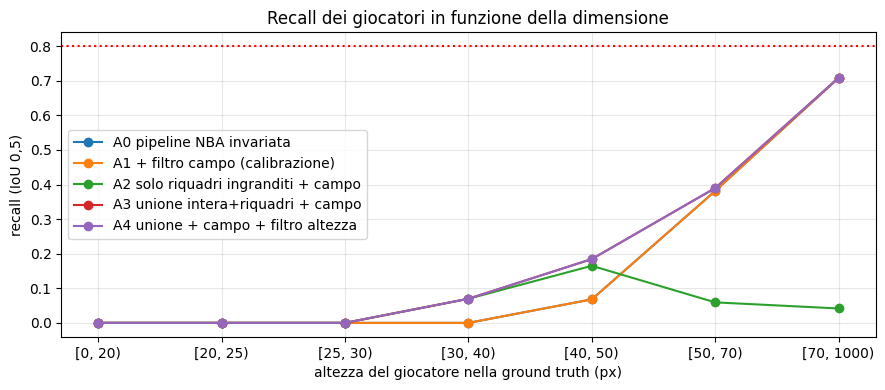

altezza minima per recall >= 0.8 : {'A0 pipeline NBA invariata': None, 'A1 + filtro campo (calibrazione)': None, 'A2 solo riquadri ingranditi + campo': None, 'A3 unione intera+riquadri + campo': None, 'A4 unione + campo + filtro altezza': None}


palla:   0%|          | 0/46 [00:00<?, ?it/s]

Palla: {'frame_con_palla_visibile': 6, 'frame_annotati': 46, 'diametro_px_mediana': 9.3, 'diametro_px_min_max': [6.0, 15.3], 'recall_intera': 0.0, 'rilevamenti_sbagliati_per_frame_intera': 0.348, 'recall_riquadri': 0.0, 'rilevamenti_sbagliati_per_frame_riquadri': 0.913}
Diametro previsto dalla calibrazione (sezione C, palla a terra): 2.2-9.7 px | misurato: [6.0, 15.3]


,requisito,soglia,DR3,soddisfatto,nota
0,Diametro della palla,>= 15 px (palle viste in addestramento: 15-26 px),9.3 px (mediana),False,servirebbe una risoluzione circa 1.6 volte mag...
1,Altezza dei giocatori per recall >= 0.8,non raggiunta,46 px (mediana),False,configurazione migliore: A1 + filtro campo (ca...
2,Movimento della camera,<= 2 px tra frame consecutivi,0.05 px (mediana),True,oltre la soglia l'immagine è mossa (vedi Frosi...
3,Calibrazione del campo,"keypoint automatici, oppure >= 8 punti visibili","manuale, 17 punti, errore LOO 19.8 cm",True,i keypoint automatici falliscono (notebook 19)
4,Frame rate,>= 25 fps,29.97 fps,True,le regole degli eventi sono espresse in frame ...
5,Punteggio in sovrimpressione,necessario solo per la lettura del punteggio,assente,False,punteggio non disponibile


Aggiornato /content/drive/MyDrive/Tesi_Basket/events_amatoriali/dr3_c1/riepilogo.json


In [19]:
# K2. Valutazione sulla ground truth (servono le celle delle sezioni B e D eseguite in questa sessione)
import zipfile, yaml
from scipy.optimize import linear_sum_assignment
assert 'detect' in globals() and 'plausible' in globals() and 'Hm' in globals(), 'Esegui prima le sezioni B e D'
GT_DIR = ROOT / 'datasets' / GT_NAME; GT_ZIP = ROOT / 'datasets' / f'{GT_NAME}_annotato.zip'
assert GT_ZIP.is_file(), f'Manca {GT_ZIP}: esporta la ground truth da Roboflow'
BALL_PX_NBA = (15.0, 20.6, 26.0)      # diametro della palla nei frame NBA di test di E4 (5° percentile, mediana, 95° percentile)
H_RECALL_REQ = 0.80                   # recall richiesta per definire l'altezza minima dei giocatori

tmp = (Path('/content') if IN_COLAB else ROOT / '_cache') / f'{GT_NAME}_rf'
if tmp.exists(): shutil.rmtree(tmp)
zipfile.ZipFile(GT_ZIP).extractall(tmp)
names = yaml.safe_load(open(next(tmp.rglob('data.yaml'))))['names']
names = [names[k] for k in sorted(names)] if isinstance(names, dict) else names
def cls_of(*keys): return next((i for i, n in enumerate(names) if any(k in n.lower() for k in keys)), None)
C_PL, C_REF, C_BALL = cls_of('player', 'giocator'), cls_of('ref', 'arbitr'), cls_of('ball', 'palla')
assert C_PL is not None, f'classe player non trovata in {names}'

GT = {}
for lp in tmp.rglob('*.txt'):
    if lp.parent.name != 'labels': continue
    stem = lp.stem.split('_jpg')[0].split('.rf.')[0]; img = GT_DIR / 'images' / f'{stem}.jpg'
    if not img.is_file(): continue
    a = np.loadtxt(lp, ndmin=2) if lp.stat().st_size else np.zeros((0, 5))
    a = a[:, :5]
    GT[stem] = np.c_[a[:, 0], (a[:, 1] - a[:, 3] / 2) * W, (a[:, 2] - a[:, 4] / 2) * H, (a[:, 1] + a[:, 3] / 2) * W, (a[:, 2] + a[:, 4] / 2) * H]
n_estr = len(list((GT_DIR / 'images').glob('*.jpg')))
print(f'frame annotati: {len(GT)} su {n_estr} estratti ({n_estr - len(GT)} cancellati come non di gioco)')
assert len(GT) >= 10

def iou_m(a, b):
    tl = np.maximum(a[:, None, :2], b[None, :, :2]); br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(br - tl, 0, None), 2); ar = lambda x: np.prod(x[:, 2:] - x[:, :2], 1)
    return inter / (ar(a)[:, None] + ar(b)[None] - inter + 1e-9)
def match(g, d, thr):
    mg, md_ = np.zeros(len(g), bool), np.zeros(len(d), bool)
    if len(g) and len(d):
        M = iou_m(g, d); r, c = linear_sum_assignment(-M); ok = M[r, c] >= thr; mg[r[ok]] = True; md_[c[ok]] = True
    return mg, md_

# --- giocatori: ablation ---
CONFIGS = {'A0 pipeline NBA invariata': ('intera', False, False, False),
           'A1 + filtro campo (calibrazione)': ('intera', True, False, False),
           'A2 solo riquadri ingranditi + campo': ('riquadri', True, False, False),
           'A3 unione intera+riquadri + campo': ('unione', True, False, False),
           'A4 unione + campo + filtro altezza': ('unione', True, True, False)}
if MASKS: CONFIGS['A5 + maschere'] = ('unione', True, True, True)
cache_det, per_gt, rows = {}, [], []
for stem, g in tqdm(GT.items(), desc='giocatori'):
    f = cv2.imread(str(GT_DIR / 'images' / f'{stem}.jpg'))
    gp, gr = g[g[:, 0] == C_PL, 1:], (g[g[:, 0] == C_REF, 1:] if C_REF is not None else np.zeros((0, 4)))
    for mode in ['intera', 'riquadri', 'unione']: cache_det[(stem, mode)] = detect(f, mode)
    for cname, (mode, campo, alt, masch) in CONFIGS.items():
        d = cache_det[(stem, mode)]
        keep = np.ones(len(d), bool)
        if campo and len(d): keep &= in_court(feet_world(d), OUT_MARGIN_M)
        if alt and len(d): keep &= plausible(d)
        if masch and MASKS and len(d): keep &= np.array([not in_mask((x1 + x2) / 2, y2) for x1, y1, x2, y2 in d[:, :4]], bool)
        d = d[keep][:, :4]
        for thr in [0.5, 0.3]:
            mg, md_ = match(gp, d, thr)
            _, mr = match(gr, d[~md_], thr)                      # rilevamenti che coincidono con un arbitro: ignorati
            rows.append({'config': cname, 'iou': thr, 'frame': stem, 'tp': int(mg.sum()), 'fn': int((~mg).sum()),
                         'fp': int((~md_).sum() - mr.sum())})
            if thr == 0.5:
                for box, ok in zip(gp, mg): per_gt.append({'config': cname, 'altezza_px': box[3] - box[1], 'trovato': ok})
R = pd.DataFrame(rows).groupby(['iou', 'config'], sort=False)[['tp', 'fp', 'fn']].sum()
R['precisione'] = (R.tp / (R.tp + R.fp)).round(3); R['recall'] = (R.tp / (R.tp + R.fn)).round(3)
R['F1'] = (2 * R.tp / (2 * R.tp + R.fp + R.fn)).round(3); R['FP_per_frame'] = (R.fp / len(GT)).round(2)
display(R); R.to_csv(RES / 'gt_ablation_giocatori.csv')

# --- recall per altezza ---
PG = pd.DataFrame(per_gt); BINS = [0, 20, 25, 30, 40, 50, 70, 1000]
PG['fascia'] = pd.cut(PG.altezza_px, BINS, right=False)
RH = PG.groupby(['config', 'fascia'], observed=False, sort=False).trovato.agg(['mean', 'count']).unstack(0)
display(RH.round(2)); RH.to_csv(RES / 'gt_recall_per_altezza.csv')
best = R.loc[0.5].F1.idxmax()
fig, ax = plt.subplots(figsize=(9, 4))
for c in CONFIGS:
    m = PG[PG.config == c].groupby('fascia', observed=False).trovato.mean()
    ax.plot([str(i) for i in m.index], m.values, 'o-', label=c)
ax.axhline(H_RECALL_REQ, color='r', ls=':'); ax.set_xlabel('altezza del giocatore nella ground truth (px)'); ax.set_ylabel('recall (IoU 0,5)')
ax.legend(); ax.grid(alpha=.3); ax.set_title('Recall dei giocatori in funzione della dimensione')
plt.tight_layout(); plt.savefig(RES / 'gt_recall_per_altezza.png', dpi=160); plt.show()
def h_min(c):                                   # altezza minima da cui la recall resta >= soglia in tutte le fasce con almeno 5 giocatori
    m = PG[PG.config == c].groupby('fascia', observed=False).trovato.agg(['mean', 'count']); m = m[m['count'] >= 5]
    for i in range(len(m)):
        if (m['mean'].iloc[i:] >= H_RECALL_REQ).all(): return float(m.index[i].left)
    return None
HMIN = {c: h_min(c) for c in CONFIGS}
print('altezza minima per recall >=', H_RECALL_REQ, ':', HMIN)

# --- palla ---
ball = YOLO(str(BALL_WEIGHTS)) if 'ball' not in globals() else ball
def ball_detect(f, mode):
    if mode == 'intera':
        r = ball.predict(f, conf=0.25, imgsz=1280, verbose=False)[0]
        return np.c_[r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()].reshape(-1, 5)
    y0, y1 = int(max(0, ROI_Y[0] - 0.15) * H), int(ROI_Y[1] * H)   # la palla in aria può stare sopra la striscia del campo
    tw = W / (N_TILES - (N_TILES - 1) * TILE_OVERLAP); out = []
    for k in range(N_TILES):
        x0 = int(round(k * tw * (1 - TILE_OVERLAP))); x1 = min(W, int(round(x0 + tw))); tile = f[y0:y1, x0:x1]; s = 1280 / tile.shape[1]
        r = ball.predict(cv2.resize(tile, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC), conf=0.25, imgsz=1280, verbose=False)[0]
        out.append(np.c_[r.boxes.xyxy.cpu().numpy() / s + [x0, y0, x0, y0], r.boxes.conf.cpu().numpy()])
    return np.concatenate(out)
brow = []
for stem, g in tqdm(GT.items(), desc='palla'):
    f = cv2.imread(str(GT_DIR / 'images' / f'{stem}.jpg'))
    gb = g[g[:, 0] == C_BALL, 1:] if C_BALL is not None else np.zeros((0, 4))
    for mode in ['intera', 'riquadri']:
        d = ball_detect(f, mode); r = {'frame': stem, 'modo': mode, 'palla_visibile': len(gb) > 0}
        if len(d):
            x1, y1, x2, y2, _ = d[d[:, 4].argmax()]; cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
            r['giusta'] = bool(len(gb)) and any(bx1 - 3 <= cx <= bx2 + 3 and by1 - 3 <= cy <= by2 + 3 for bx1, by1, bx2, by2 in gb)
            r['sbagliata'] = not r['giusta']
        else: r['giusta'] = r['sbagliata'] = False
        if len(gb): r['diametro_px'] = float(np.mean([(gb[0, 2] - gb[0, 0]), (gb[0, 3] - gb[0, 1])]))
        brow.append(r)
B = pd.DataFrame(brow); B.to_csv(RES / 'gt_palla.csv', index=False)
vis = B[B.palla_visibile]
BALL_GT = {'frame_con_palla_visibile': int(vis.frame.nunique()), 'frame_annotati': len(GT),
           'diametro_px_mediana': round(float(vis.diametro_px.median()), 1) if len(vis) else None,
           'diametro_px_min_max': [round(float(vis.diametro_px.min()), 1), round(float(vis.diametro_px.max()), 1)] if len(vis) else None}
for mode in ['intera', 'riquadri']:
    q = B[B.modo == mode]
    BALL_GT[f'recall_{mode}'] = round(float(q[q.palla_visibile].giusta.mean()), 3) if len(vis) else None
    BALL_GT[f'rilevamenti_sbagliati_per_frame_{mode}'] = round(float(q.sbagliata.mean()), 3)
print('Palla:', BALL_GT)
print(f"Diametro previsto dalla calibrazione (sezione C, palla a terra): {BALL_PX['min']}-{BALL_PX['max']} px | misurato: {BALL_GT['diametro_px_min_max']}")

# --- movimento della camera e fps ---
HANN = cv2.createHanningWindow((W // 2, H // 2), cv2.CV_32F); mv = []
cap = cv2.VideoCapture(str(CLIP))
for fi in np.linspace(0, N - 2, 30).astype(int):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(fi)); ok1, f1 = cap.read(); ok2, f2 = cap.read()
    if not (ok1 and ok2): continue
    g = [cv2.cvtColor(cv2.resize(x, (W // 2, H // 2)), cv2.COLOR_BGR2GRAY).astype(np.float32) for x in (f1, f2)]
    (dx, dy), _ = cv2.phaseCorrelate(g[0], g[1], HANN); mv.append(2 * float(np.hypot(dx, dy)))
cap.release()
r = subprocess.run(['ffprobe', '-v', 'error', '-select_streams', 'v:0', '-show_entries', 'stream=r_frame_rate', '-of', 'csv=p=0', str(SRC)], capture_output=True, text=True)
num, den = r.stdout.strip().split('/'); FPS_SRC = round(float(num) / float(den), 2)

# --- tabella dei requisiti ---
dm = BALL_GT['diametro_px_mediana'] or float(np.nanmedian(D))
hm = HMIN.get(best); h_gt = PG[PG.config == best].altezza_px
REQ = pd.DataFrame([
    {'requisito': 'Diametro della palla', 'soglia': f'>= {BALL_PX_NBA[0]:.0f} px (palle viste in addestramento: {BALL_PX_NBA[0]:.0f}-{BALL_PX_NBA[2]:.0f} px)',
     'DR3': f'{dm:.1f} px (mediana)', 'soddisfatto': dm >= BALL_PX_NBA[0],
     'nota': f'servirebbe una risoluzione circa {BALL_PX_NBA[0] / dm:.1f} volte maggiore (larghezza ~{int(W * BALL_PX_NBA[0] / dm)} px) con la stessa inquadratura'},
    {'requisito': f'Altezza dei giocatori per recall >= {H_RECALL_REQ}', 'soglia': f'>= {hm:.0f} px' if hm is not None else 'non raggiunta',
     'DR3': f'{h_gt.median():.0f} px (mediana); {100 * (h_gt < hm).mean():.0f}% dei giocatori sotto soglia' if hm is not None else f'{h_gt.median():.0f} px (mediana)',
     'soddisfatto': hm is not None and (h_gt >= hm).mean() >= 0.9, 'nota': f'configurazione migliore: {best}'},
    {'requisito': 'Movimento della camera', 'soglia': '<= 2 px tra frame consecutivi', 'DR3': f'{np.median(mv):.2f} px (mediana)',
     'soddisfatto': float(np.median(mv)) <= 2, 'nota': 'oltre la soglia l\'immagine è mossa (vedi Frosinone)'},
    {'requisito': 'Calibrazione del campo', 'soglia': 'keypoint automatici, oppure >= 8 punti visibili',
     'DR3': f"manuale, {CAL['n_punti']} punti, errore LOO {CAL['errore_loo_cm_medio']} cm", 'soddisfatto': True,
     'nota': 'i keypoint automatici falliscono (notebook 19)'},
    {'requisito': 'Frame rate', 'soglia': '>= 25 fps', 'DR3': f'{FPS_SRC} fps', 'soddisfatto': FPS_SRC >= 25, 'nota': 'le regole degli eventi sono espresse in frame a 30 fps'},
    {'requisito': 'Punteggio in sovrimpressione', 'soglia': 'necessario solo per la lettura del punteggio', 'DR3': 'assente',
     'soddisfatto': False, 'nota': 'punteggio non disponibile'},
])
display(REQ); REQ.to_csv(RES / 'requisiti.csv', index=False)
sp = RES / 'riepilogo.json'; s = json.loads(sp.read_text()) if sp.is_file() else {}
s['ground_truth'] = {'frame': len(GT), 'cancellati_non_di_gioco': n_estr - len(GT),
                     'giocatori_iou05': R.loc[0.5][['precisione', 'recall', 'F1', 'FP_per_frame']].to_dict('index'),
                     'altezza_min_recall_px': HMIN, 'palla': BALL_GT, 'movimento_camera_px': round(float(np.median(mv)), 2), 'fps_video': FPS_SRC}
sp.write_text(json.dumps(s, indent=2, ensure_ascii=False, default=str)); print('Aggiornato', sp)